# 02 - Exact method: MILP solved by branch-and-bound

The CVRP is written as a Mixed-Integer Linear Program (two-index vehicle-flow model with
Miller-Tucker-Zemlin load variables) and solved with the open-source solver **HiGHS** through PuLP.
HiGHS uses LP-based branch-and-bound with cutting planes (branch-and-cut), the method of Lecture 5.

$$\min \sum_{i \in V}\sum_{j \in V, j \ne i} c_{ij} x_{ij}$$

subject to: each customer is left once and entered once, at most $K$ routes leave the depot, every route returns,
and the MTZ load constraints $u_j \ge u_i + q_j - Q(1 - x_{ij})$ with $q_i \le u_i \le Q$.
The full model is in `src/exact_milp.py`; the report lists every constraint with its meaning.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

from src.report_analysis import plot_routes, style
from src.checker import check_solution
from src.data_loader import load_bks, load_instance

style()

In [2]:
from src.exact_milp import build_model, lp_relaxation_bound, solve_exact

inst = load_instance("P-n16-k8")
_, optimum = load_bks("P-n16-k8")
for strengthened in (False, True):
    prob, x, u = build_model(inst, strengthened=strengthened)
    n_bin = sum(v.cat == "Integer" for v in prob.variables())
    print(f"{'strengthened' if strengthened else 'basic':12}: {n_bin} binary + {len(prob.variables()) - n_bin} "
          f"continuous variables, {len(prob.constraints)} constraints")

basic       : 240 binary + 15 continuous variables, 242 constraints
strengthened: 240 binary + 15 continuous variables, 243 constraints


## Solve the 15-customer instance with both formulations

The *strengthened* model adds two valid inequalities: a lower bound on the number of routes
$\sum_j x_{0j} \ge \lceil \sum_i q_i / Q \rceil$ and the lifted MTZ constraints of Kara, Laporte & Bektas (2004).
Both cut off fractional LP solutions without removing any integer solution.

In [3]:
results = {}
for strengthened in (False, True):
    lp, _ = lp_relaxation_bound(inst, strengthened)
    res = solve_exact(inst, time_limit=120, strengthened=strengthened)
    results[res.model] = res
    print(f"{res.model:12}: status={res.status}, cost={res.cost} (optimum {optimum}), "
          f"LP bound={lp:.1f} (root gap {100 * (optimum - lp) / optimum:.1f} %), "
          f"time={res.runtime:.1f} s, branch-and-bound nodes={res.nodes}")

basic       : status=optimal, cost=450 (optimum 450), LP bound=140.6 (root gap 68.8 %), time=30.0 s, branch-and-bound nodes=12465


strengthened: status=optimal, cost=450 (optimum 450), LP bound=395.0 (root gap 12.2 %), time=4.1 s, branch-and-bound nodes=602


independent check: feasible - recomputed cost 450


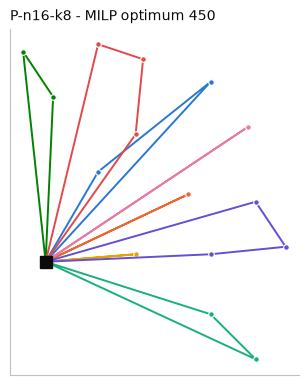

In [4]:
res = results["strengthened"]
check = check_solution(inst, res.routes)
print("independent check:", "feasible" if check.feasible else check.errors, "- recomputed cost", check.cost)
fig, ax = plt.subplots(figsize=(4.5, 4.5))
plot_routes(ax, inst, res.routes, f"P-n16-k8 - MILP optimum {check.cost}")
plt.show()

## Results of experiment E1 (all small and medium instances, 300 s limit)

Produced by `python -m src.experiments exact`; the table is `results/tables/T2_exact.md`.
*Status "time limit"* means HiGHS stopped before proving optimality: the cost is the best integer solution found
and the lower bound is what branch-and-bound could prove. PuLP's own `LpStatus` would still say
"Optimal" in that case, which is why `solve_exact` reads the HiGHS model status directly.

In [5]:
display(Markdown((ROOT / "results/tables/T2_exact.md").read_text()))

| Instance | n | Model | Status | Cost | Lower bound | MIP gap % | Gap to opt. % | Time s | Nodes | LP bound | Root gap % |
|-----------|-----:|---------------|-------------|-------:|--------:|-------:|-------:|--------:|---------:|--------:|-------:|
| P-n16-k8 | 15 | basic | optimal | 450 | 450.00 | 0.00 | 0.00 | 29.60 | 12,465 | 140.60 | 68.80 |
| P-n16-k8 | 15 | strengthened | optimal | 450 | 450.00 | 0.00 | 0.00 | 3.30 | 602 | 395.00 | 12.20 |
| P-n19-k2 | 18 | basic | time limit | 218 | 166.00 | 23.85 | 2.83 | 300.10 | 110,071 | 128.20 | 39.50 |
| P-n19-k2 | 18 | strengthened | optimal | 212 | 212.00 | 0.00 | 0.00 | 89.80 | 27,035 | 184.00 | 13.20 |
| P-n20-k2 | 19 | basic | time limit | 216 | 170.00 | 21.30 | 0.00 | 300.10 | 100,067 | 141.20 | 34.60 |
| P-n20-k2 | 19 | strengthened | optimal | 216 | 216.00 | 0.00 | 0.00 | 49.30 | 12,428 | 195.00 | 9.70 |
| E-n22-k4 | 21 | basic | time limit | 379 | 291.00 | 23.22 | 1.07 | 300.10 | 68,882 | 225.80 | 39.80 |
| E-n22-k4 | 21 | strengthened | time limit | 375 | 349.00 | 6.93 | 0.00 | 300.10 | 86,521 | 308.50 | 17.70 |
| P-n22-k2 | 21 | basic | time limit | 216 | 176.00 | 18.52 | 0.00 | 300.10 | 80,752 | 150.00 | 30.60 |
| P-n22-k2 | 21 | strengthened | optimal | 216 | 216.00 | 0.00 | 0.00 | 50.60 | 11,005 | 198.00 | 8.30 |
| P-n23-k8 | 22 | basic | time limit | 545 | 393.00 | 27.89 | 3.02 | 300.10 | 41,188 | 163.40 | 69.10 |
| P-n23-k8 | 22 | strengthened | time limit | 565 | 450.00 | 20.35 | 6.81 | 300.10 | 58,577 | 346.00 | 34.60 |
| B-n31-k5 | 30 | basic | time limit | 705 | 217.00 | 69.22 | 4.91 | 300.20 | 51,479 | 69.60 | 89.60 |
| B-n31-k5 | 30 | strengthened | time limit | 695 | 606.00 | 12.81 | 3.42 | 300.20 | 42,754 | 485.00 | 27.80 |
| A-n32-k5 | 31 | basic | time limit | 825 | 445.00 | 46.06 | 5.23 | 300.20 | 30,475 | 361.80 | 53.80 |
| A-n32-k5 | 31 | strengthened | time limit | 795 | 611.00 | 23.14 | 1.40 | 300.20 | 11,996 | 584.50 | 25.40 |
| A-n37-k5 | 36 | basic | time limit | 737 | 511.00 | 30.66 | 10.16 | 300.20 | 11,115 | 448.40 | 33.00 |
| A-n37-k5 | 36 | strengthened | time limit | 688 | 562.00 | 18.31 | 2.84 | 300.20 | 16,907 | 538.50 | 19.50 |
| P-n40-k5 | 39 | basic | time limit | 490 | 356.00 | 27.35 | 6.99 | 300.30 | 12,489 | 322.80 | 29.50 |
| P-n40-k5 | 39 | strengthened | time limit | 491 | 410.00 | 16.50 | 7.21 | 300.30 | 15,621 | 404.00 | 11.80 |
| A-n45-k7 | 44 | basic | time limit | 1,429 | 514.00 | 64.03 | 24.69 | 300.40 | 21,879 | 441.70 | 61.50 |
| A-n45-k7 | 44 | strengthened | time limit | 1,322 | 742.00 | 43.87 | 15.36 | 300.30 | 9,626 | 725.50 | 36.70 |
| E-n51-k5 | 50 | basic | time limit | 686 | 420.00 | 38.78 | 31.67 | 300.40 | 6,055 | 383.70 | 26.40 |
| E-n51-k5 | 50 | strengthened | time limit | 615 | 462.00 | 24.88 | 18.04 | 300.30 | 14,808 | 454.00 | 12.90 |


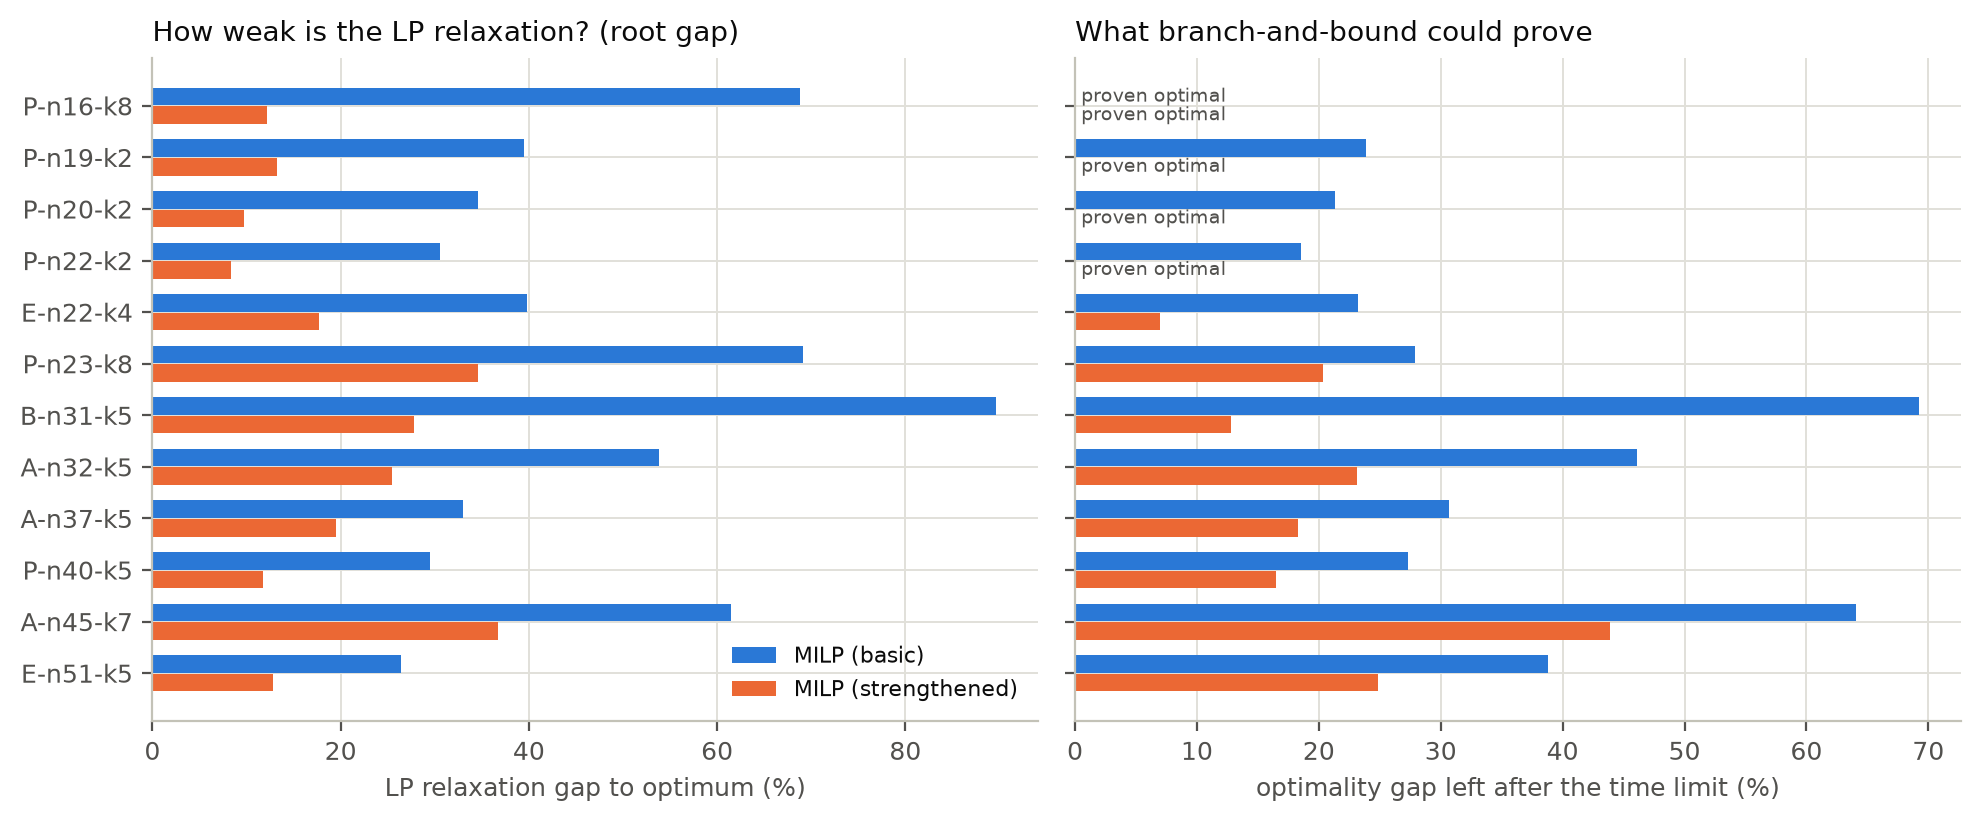

In [6]:
display(Image(str(ROOT / "results/figures/F4_exact_bounds.png")))